In [1]:
%load_ext autoreload
%autoreload 2
    
import json
import math
import pandas as pd
import os
import sys
import asyncio

# Get the absolute path of the parent directory (your project root)
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))

# Add it to the system path if it's not already there
if project_root not in sys.path:
    sys.path.append(project_root)

from affective_bridge.providers.ollama_provider import OllamaProvider
from affective_bridge.prompts import SYSTEM_PROMPT
from affective_bridge.schemas import ForensicAnalysis

# ---------------------------------------------------------
# 1. THE LLM INTERFACE
# ---------------------------------------------------------
async def run_affective_bridge(text: str) -> dict:
    """
    Run Affective-Bridge with local Ollama provider.
    """
    provider = OllamaProvider(model="llama3", temperature=0)
    analysis: ForensicAnalysis = await provider.get_analysis(text, SYSTEM_PROMPT)
    return analysis

In [2]:
# Limit concurrent requests to 1 when testing with local LLMs (like Ollama + Llama 3).
# Complex, schema-driven prompts require high attention and token generation. 
# Allowing multiple concurrent requests will cause VRAM exhaustion, queue thrashing, 
# and ReadTimeout errors, or cause the model to drop instructions.
SEM = asyncio.Semaphore(1)  # 1–3 for Ollama
async def run_affective_bridge_limited(text: str) -> dict:
    async with SEM:
        return await run_affective_bridge(text)

In [3]:
import matplotlib
# ---------------------------------------------------------
# 2. THE TEST MATRIX
# ---------------------------------------------------------
async def run_evaluation_suite():
    test_cases = [
        # 1. Defensive Apathy (Masking vulnerability or fear of loss)
        "I'm perfectly fine. It's just a job, I can easily find another one.",
        # 2. Congruent Positive - Short (Null Hypothesis Check: Should score 0.0)
        "Everything is literally perfect!",
        # 3. Congruent Neutral (Null Hypothesis Check: Should score 0.0)
        "It's fine, really.",
        # 4. Burden Minimization (Masking overwhelm and resentment)
        "I'll just handle the rewrite myself over the weekend. It's really not a big deal at all.",
        # 5. Defensive Rationalization (High-arousal overcompensation masking severe anxiety)
        "I am absolutely 100% ready for the core database migration this weekend. The schema conflicts are a nightmare and I haven't slept, but I thrive on this pressure!",
        # 6. The Passive-Aggressive Sandwich (Overt praise masking frustration)
        "Great job everyone! We probably didn't need to rewrite the entire logic and push the sprint back two weeks, but it's whatever. We'll just work late.",
        # 7. Toxic Positivity (Masking severe burnout)
        "I'm so incredibly grateful for this opportunity to take on three people's workloads! It’s a fantastic learning experience and I am just radiating positivity today.",
        # 8. Congruent Negative (Null Hypothesis Check: Should score 0.0 dissonance, low valence/arousal)
        "I am completely exhausted and honestly very disappointed that the project got canceled. I don't have the energy to talk about it right now.",
        # 9. Feigned Apathy (Suppressing intense anger/hurt)
        "Oh, you promoted the junior dev who started last month over me? Cool. No, honestly, good for him. It doesn't matter to me at all, it's just a title.",
        # 10. The False Apology (Masking contempt/blame)
        "I'm sorry you felt offended by my code review comments. I guess I just have a higher standard for architectural integrity, but I'll try to use softer words next time.",
        # 11. Resentful Compliance (Masking resistance)
        "Sure, I can absolutely drop everything I'm doing to fix the typo in your presentation. Happy to help the team.",
        # 12. Imposter Syndrome / Defensive Over-explanation (Masking panic)
        "Obviously I understand the new framework perfectly. I mean, the documentation is a sparse, and the compiler keeps throwing weird pointer errors, but I totally have it under control. Don't even worry about it.",
        # 13. Congruent High Joy (Null Hypothesis Check: Should score 0.0 dissonance, high valence/arousal)
        "We finally got the funding! I am literally jumping up and down, this is the best day of my entire career!",
        # 14. Deflection / Guilt (Masking culpability)
        "I'm totally focused on moving forward and finding solutions. Who dropped the production database isn't the point right now, what matters is our team synergy.",
        # 15. The Escalated "Fine" (Masking imminent rage)
        "I said I am fine. There is absolutely no problem. We can do it exactly your way since you clearly know best."
    ]

    results = []

    # Call engine
    tasks = [run_affective_bridge_limited(text) for text in test_cases]
    analyses = await asyncio.gather(*tasks, return_exceptions=True)

    # Flatten into a structured row
    for text, analysis in zip(test_cases, analyses):
        if isinstance(analysis, Exception):
            print(f"Failed on input: '{text}'. Error: {repr(analysis)}")
            continue
            
        results.append({
            "Input Fragment": text,
            "Alibi": analysis.alibi,
            "Alibi V": analysis.alibi_valence,
            "Alibi A": analysis.alibi_arousal,
            "Glitch": analysis.glitch,
            "Silent Narrative": analysis.silent_narrative,
            "Silent V": analysis.silent_valence,
            "Silent A": analysis.silent_arousal,
            "Dissonance": analysis.dissonance,
            "Reasoning": analysis.psychological_evaluation
        })

    df = pd.DataFrame(results)
    # Shift the DataFrame index to start at 1 instead of 0
    df.index = df.index + 1
    
    return df

df = await run_evaluation_suite()

In [7]:
# Save the golden baseline for future regression testing
df.to_csv("baseline_evaluation_matrix.csv", index_label="Case")

In [8]:
# Truncate any column longer than 50 characters
pd.set_option('display.max_colwidth', 50)

def truncate_text(text):
        if isinstance(text, str) and len(text) > 50:
            return text[:47] + "..."
        return text
# Pandas styling to make the Dissonance column pop
styled_df = df.style.background_gradient(
    subset=["Dissonance"], cmap="Reds", vmin=0.0, vmax=1.0
).format({
    "Dissonance": "{:.3f}",
    "Alibi V": "{:.2f}",
    "Alibi A": "{:.2f}",
    "Silent V": "{:.2f}",
    "Silent A": "{:.2f}",
    "Input Fragment": truncate_text,
    "Reasoning": truncate_text
})
display(styled_df)

,Input Fragment,Alibi,Alibi V,Alibi A,Glitch,Silent Narrative,Silent V,Silent A,Dissonance,Reasoning
1,"I'm perfectly fine. It's just a job, I can easi...",calmness,0.40,0.20,just a job... easily find another one,anxiety and uncertainty about the job situation,-0.30,0.50,0.341,Alibi Quote: 'I'm perfectly fine'. Glitch Quote...
2,Everything is literally perfect!,satisfaction,0.60,0.30,nan,satisfaction,0.60,0.30,0.000,Alibi Quote: 'Everything is literally perfect!'...
3,"It's fine, really.",satisfaction,0.40,0.20,nan,satisfaction,0.40,0.20,0.000,"Alibi Quote: 'It's fine, really'. Glitch Quote:..."
4,I'll just handle the rewrite myself over the we...,unbothered willingness,0.20,0.20,just handle the rewrite myself,resentment and overwhelm,-0.60,0.70,0.422,Alibi Quote: 'It's really not a big deal at all...
5,I am absolutely 100% ready for the core databas...,invigorated excitement,0.80,0.90,absolutely 100%... thrive,severe anxiety and exhaustion masking as adrenaline,-0.70,0.85,0.671,Alibi Quote: 'absolutely 100% ready... thrive'....
6,Great job everyone! We probably didn't need to ...,enthusiastic approval,0.80,0.70,probably didn't need to... push the sprint back,frustration and resentment over wasted effort,-0.60,0.50,0.632,Alibi Quote: 'Great job everyone!'. Glitch Quot...
7,I'm so incredibly grateful for this opportunity...,enthusiastic gratitude,0.90,0.80,nan,enthusiastic gratitude,0.90,0.80,0.000,Alibi Quote: 'incredibly grateful... radiating ...
8,I am completely exhausted and honestly very dis...,disappointment,-0.40,0.20,don't have the energy to talk about it right now,anger and frustration over the project's cancellation,-0.70,0.60,0.224,Alibi Quote: 'completely exhausted... very disa...
9,"Oh, you promoted the junior dev who started las...",indifference,0.20,0.10,doesn't matter to me at all,disappointment and frustration over perceived injustice,-0.50,0.40,0.341,Alibi Quote: 'it's just a title'. Glitch Quote:...
10,I'm sorry you felt offended by my code review c...,apologetic regret,0.40,0.20,just have a higher standard,frustration and disappointment over perceived criticism,-0.50,0.30,0.405,Alibi Quote: 'I'm sorry you felt...'. Glitch Qu...


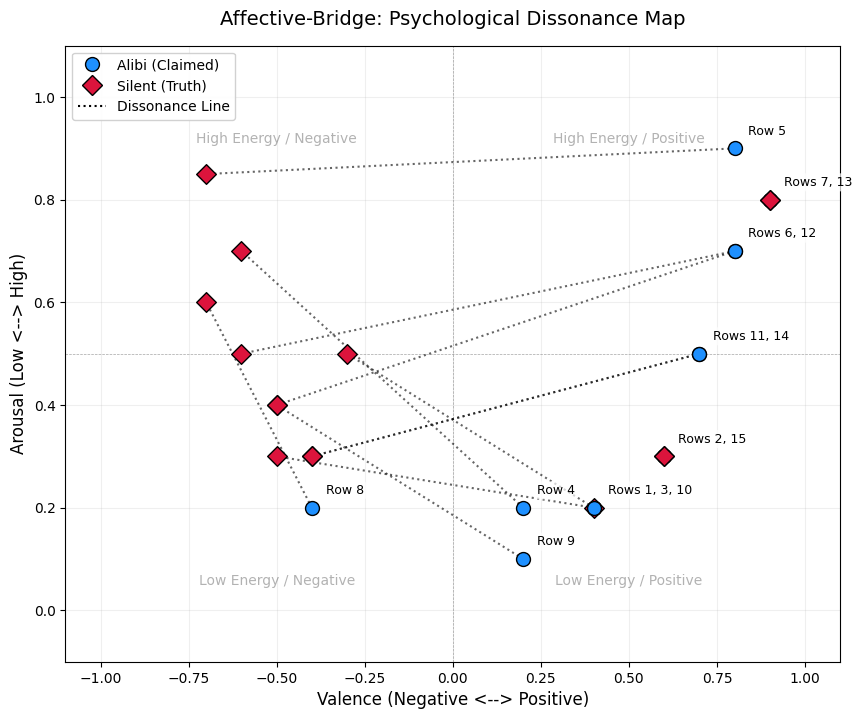

In [9]:
import matplotlib.pyplot as plt

def plot_affective_grid(df):
    plt.figure(figsize=(10, 8))
    
    # Setup the grid boundaries
    # Valence is [-1, 1], Arousal is [0, 1]
    plt.xlim(-1.1, 1.1)
    plt.ylim(-0.1, 1.1)
    
    # Draw the crosshairs (neutral axes)
    plt.axhline(0.5, color='gray', linestyle='--', linewidth=0.5, alpha=0.7) # Mid-arousal
    plt.axvline(0, color='gray', linestyle='--', linewidth=0.5, alpha=0.7)   # Neutral valence
    
    # Add quadrant labels for context
    plt.text(0.5, 0.91, 'High Energy / Positive', alpha=0.3, fontsize=10, ha='center')
    plt.text(-0.5, 0.91, 'High Energy / Negative', alpha=0.3, fontsize=10, ha='center')
    plt.text(0.5, 0.05, 'Low Energy / Positive', alpha=0.3, fontsize=10, ha='center')
    plt.text(-0.5, 0.05, 'Low Energy / Negative', alpha=0.3, fontsize=10, ha='center')

# 1. Pre-group the row indices by their Alibi coordinates
    label_map = {}
    for index, row in df.iterrows():
        coord = (row['Alibi V'], row['Alibi A'])
        if coord not in label_map:
            label_map[coord] = []
        label_map[coord].append(str(index))

    # 2. Draw the markers and lines (overlapping shapes just stack visually)
    for index, row in df.iterrows():
        av, aa = row['Alibi V'], row['Alibi A']
        sv, sa = row['Silent V'], row['Silent A']
        
        # Plot Alibi (Blue Circle)
        plt.scatter(av, aa, color='dodgerblue', s=100, zorder=3, edgecolors='black')
        
        # Plot Silent Narrative (Red Diamond)
        plt.scatter(sv, sa, color='crimson', s=100, marker='D', zorder=3, edgecolors='black')
        
        # Draw the Dissonance Line
        if (av, aa) != (sv, sa):
            plt.plot([av, sv], [aa, sa], color='black', linestyle=':', linewidth=1.5, alpha=0.6, zorder=2)

    # 3. Apply the grouped text labels just ONCE per unique coordinate
    for (av, aa), indices in label_map.items():
        # If one row, print "Row 1". If multiple, print "Rows 2, 3, 8"
        label_text = f"Row {indices[0]}" if len(indices) == 1 else f"Rows {', '.join(indices)}"
        
        plt.annotate(
            label_text, 
            (av, aa), 
            textcoords="offset points", 
            xytext=(10, 10), # Pushed slightly further out to accommodate wider text
            fontsize=9,
            bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7, ec="none") # Adds a subtle background to make text pop
        )

    # Title and Labels
    plt.title("Affective-Bridge: Psychological Dissonance Map", fontsize=14, pad=15)
    plt.xlabel("Valence (Negative <--> Positive)", fontsize=12)
    plt.ylabel("Arousal (Low <--> High)", fontsize=12)
    
    # Custom Legend
    from matplotlib.lines import Line2D
    legend_elements = [
        Line2D([0], [0], marker='o', color='w', label='Alibi (Claimed)', markerfacecolor='dodgerblue', markersize=10, markeredgecolor='black'),
        Line2D([0], [0], marker='D', color='w', label='Silent (Truth)', markerfacecolor='crimson', markersize=10, markeredgecolor='black'),
        Line2D([0], [0], color='black', linestyle=':', label='Dissonance Line')
    ]
    plt.legend(handles=legend_elements, loc='upper left', framealpha=0.9)


    plt.grid(True, alpha=0.2)
    plt.show()

plot_affective_grid(df)

### ⚖️ A/B Testing: Evaluating Prompt Modifications

**When to use this:** If you modify the core `SYSTEM_PROMPT` (e.g., adding new psychological edge cases or optimizing for a larger parameter model), use this tool to compare your new extraction metrics against the established Golden Baseline.

**Instructions:**
1. Modify the `SYSTEM_PROMPT` in the extraction engine.
2. Change the save path in the main loop to generate a new dataset (e.g., `df.to_csv("evals/my_custom_prompt_run.csv")`).
3. Update the `FILE_NEW` variable in the script below.
4. Run this cell to generate a color-coded heatmap of the dissonance shifts to ensure your changes didn't cause context dilution or regressions.

In [11]:
# --- USER CONFIGURATION ---
FILE_BASELINE = "baseline_evaluation_matrix.csv"
FILE_NEW = "example_eval_run.csv" # Update this to your new experiment's CSV
# --------------------------

# Load datasets
try:
    df_baseline = pd.read_csv(FILE_BASELINE)
    df_new = pd.read_csv(FILE_NEW)
except FileNotFoundError as e:
    print(f"Error: Could not find evaluation files. {e}")
    raise

# Merge based on the input text
merged_df = df_baseline.merge(
    df_new,
    on="Input Fragment",
    suffixes=("_old", "_new")
)

# Build comparison DataFrame
comparison_df = pd.DataFrame({
    "Input Fragment": merged_df["Input Fragment"].str[:45] + "...", 
    "Old Dissonance": merged_df["Dissonance_old"],
    "New Dissonance": merged_df["Dissonance_new"],
    "Diff": merged_df["Dissonance_new"] - merged_df["Dissonance_old"]
})

# Color-coding logic for increase vs. decrease in Dissonance
def highlight_changes(val):
    if val > 0.05:
        return 'background-color: rgba(52, 152, 219, 0.3)'  # blue (Increased Dissonance)
    elif val < -0.05:
        return 'background-color: rgba(241, 196, 15, 0.3)'  # yellow (Decreased Dissonance)
    return ''

# Render table
styled_compare = comparison_df.style.map(
    highlight_changes, subset=['Diff']
).format({
    "Old Dissonance": "{:.3f}",
    "New Dissonance": "{:.3f}",
    "Diff": "{:+.3f}"
})

display(styled_compare)

,Input Fragment,Old Dissonance,New Dissonance,Diff
0,"I'm perfectly fine. It's just a job, I can ea...",0.341,0.341,+0.000
1,Everything is literally perfect!...,0.000,0.000,+0.000
2,"It's fine, really....",0.000,0.000,+0.000
3,I'll just handle the rewrite myself over the ...,0.422,0.422,+0.000
4,I am absolutely 100% ready for the core datab...,0.671,0.671,+0.000
5,Great job everyone! We probably didn't need t...,0.632,0.632,+0.000
6,I'm so incredibly grateful for this opportuni...,0.000,0.000,+0.000
7,I am completely exhausted and honestly very d...,0.224,0.224,+0.000
8,"Oh, you promoted the junior dev who started l...",0.341,0.341,+0.000
9,I'm sorry you felt offended by my code review...,0.405,0.405,+0.000
